# Memorization and Privacy in Machine Learning
## Membership Inference Attacks and Defenses

**Author:** Aakash Tiwari, M.S. Cybersecurity, Rowan University

A membership inference attack asks: given a trained model and a person's record, can an attacker tell whether that record was in the training data?

If a model was trained on hospital or financial records, simply learning that someone was in the training set can reveal private information about them.

This notebook:
1. Trains income-prediction models on the Adult Census dataset
2. Attacks them with two membership inference attacks: a confidence threshold attack and a shadow model attack
3. Measures how overfitting changes privacy leakage
4. Tests three defenses and their effect on accuracy

In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve

os.makedirs('figures', exist_ok=True)

## 1. Load the data
Adult Census Income from the UCI Machine Learning Repository (Becker & Kohavi, 1996): 32,561 records, 30,162 after removing rows with missing values. The task is predicting whether income is above $50K.

In [2]:
url = 'https://raw.githubusercontent.com/shap/shap/master/data/adult.data'
cols = ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation',
        'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']

adult = pd.read_csv(url, header=None, names=cols, skipinitialspace=True)
adult = adult.replace('?', np.nan).dropna()
adult.shape

(30162, 15)

In [3]:
y = (adult['income'] == '>50K').astype(int).values
X = pd.get_dummies(adult.drop(columns=['income', 'fnlwgt']), dtype=int).values
print(X.shape, round(y.mean(), 3))

(30162, 103) 0.249


## 2. Split the data into roles

| Part | Size | Role |
|---|---|---|
| Members | 5,000 | Used to train the target model |
| Non-members | 5,000 | Never seen by the target model |
| Shadow pool | about 15,000 | Data the attacker owns, from the same population |

The attacker's job is to tell members from non-members.

In [4]:
X_target, X_shadow, y_target, y_shadow = train_test_split(X, y, test_size=0.5, random_state=0)
X_in, X_out, y_in, y_out = train_test_split(X_target, y_target, train_size=5000, test_size=5000, random_state=1)

members = np.r_[np.ones(len(y_in)), np.zeros(len(y_out))]
print(len(y_in), len(y_out), len(y_shadow))

5000 5000 15081


## 3. Attack 1: confidence threshold

A model is often more confident on records it trained on. The attack score is the probability the model gives to the true label. A higher score suggests the record is a member.

Two ways to measure attack success:
- **AUC:** 0.5 means the attacker is guessing, 1.0 means perfect
- **TPR at 1% FPR:** how many members the attacker catches while wrongly accusing only 1% of non-members. This measures how dangerous the attack is for individuals

In [5]:
def true_label_confidence(model, X, y):
    p = model.predict_proba(X)
    return p[np.arange(len(y)), y]

def tpr_at_fpr(labels, scores, target_fpr=0.01):
    fpr, tpr, _ = roc_curve(labels, scores)
    return tpr[np.searchsorted(fpr, target_fpr, side='right') - 1]

## 4. Does overfitting increase leakage?
Train random forests with different `max_depth` values, from very shallow to unlimited.

In [6]:
rows = []
for depth in [2, 4, 6, 8, 10, 12, 15, 20, None]:
    model = RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=0, n_jobs=-1)
    model.fit(X_in, y_in)
    train_acc = accuracy_score(y_in, model.predict(X_in))
    test_acc = accuracy_score(y_out, model.predict(X_out))
    scores = np.r_[true_label_confidence(model, X_in, y_in), true_label_confidence(model, X_out, y_out)]
    rows.append({'max_depth': 'None' if depth is None else depth,
                 'train_acc': round(train_acc, 3), 'test_acc': round(test_acc, 3),
                 'gap': round(train_acc - test_acc, 3),
                 'attack_auc': round(roc_auc_score(members, scores), 3),
                 'tpr_at_1pct_fpr': round(tpr_at_fpr(members, scores), 3)})

depth_results = pd.DataFrame(rows)
depth_results

,max_depth,train_acc,test_acc,gap,attack_auc,tpr_at_1pct_fpr
0,2,0.763,0.765,-0.002,0.500,0.010
1,4,0.835,0.834,0.001,0.502,0.009
2,6,0.849,0.841,0.008,0.506,0.011
3,8,0.861,0.852,0.009,0.512,0.010
4,10,0.874,0.858,0.017,0.520,0.008
5,12,0.893,0.860,0.033,0.531,0.010
6,15,0.918,0.861,0.058,0.553,0.014
7,20,0.966,0.858,0.107,0.581,0.000
8,None,0.992,0.847,0.145,0.621,0.000


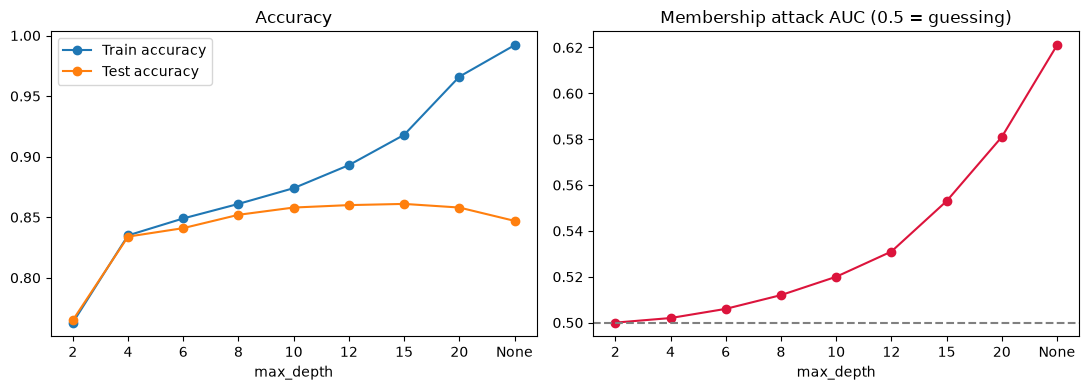

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
x = range(len(depth_results))
ax[0].plot(x, depth_results['train_acc'], marker='o', label='Train accuracy')
ax[0].plot(x, depth_results['test_acc'], marker='o', label='Test accuracy')
ax[0].set_xticks(x, depth_results['max_depth'])
ax[0].set_xlabel('max_depth')
ax[0].set_title('Accuracy')
ax[0].legend()
ax[1].plot(x, depth_results['attack_auc'], marker='o', color='crimson')
ax[1].axhline(0.5, linestyle='--', color='grey')
ax[1].set_xticks(x, depth_results['max_depth'])
ax[1].set_xlabel('max_depth')
ax[1].set_title('Membership attack AUC (0.5 = guessing)')
plt.tight_layout()
plt.savefig('figures/1_accuracy_and_leakage_vs_depth.png', dpi=200, bbox_inches='tight')
plt.show()

## 5. Attack 2: shadow models

A stronger attacker trains their own **shadow models** on their own data, where they know exactly who was a member. They then train an **attack model** that learns what membership looks like from the shadow models' outputs, and apply it to the target model.

This is the classic attack from Shokri et al. (2017), "Membership Inference Attacks against Machine Learning Models".

**Assumption:** the attacker knows the target is a random forest and uses the same model type for the shadow models. This is the standard setting from Shokri et al.

In [8]:
def attack_features(model, X, y):
    p = model.predict_proba(X)
    return np.c_[np.sort(p, axis=1), p[np.arange(len(y)), y], y]

attack_X, attack_y = [], []
for k in range(4):
    s_in, s_out, sy_in, sy_out = train_test_split(X_shadow, y_shadow, train_size=5000, test_size=5000, random_state=10 + k)
    shadow = RandomForestClassifier(n_estimators=100, random_state=k, n_jobs=-1).fit(s_in, sy_in)
    attack_X += [attack_features(shadow, s_in, sy_in), attack_features(shadow, s_out, sy_out)]
    attack_y += [np.ones(len(sy_in)), np.zeros(len(sy_out))]

attack_X = np.vstack(attack_X)
attack_y = np.concatenate(attack_y)
attack_model = GradientBoostingClassifier(random_state=0).fit(attack_X, attack_y)
attack_X.shape

(40000, 4)

In [9]:
target = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1).fit(X_in, y_in)

conf_scores = np.r_[true_label_confidence(target, X_in, y_in), true_label_confidence(target, X_out, y_out)]
shadow_scores = attack_model.predict_proba(np.vstack([attack_features(target, X_in, y_in),
                                                      attack_features(target, X_out, y_out)]))[:, 1]

pd.DataFrame({'attack': ['Confidence threshold', 'Shadow models'],
              'auc': [round(roc_auc_score(members, s), 3) for s in [conf_scores, shadow_scores]],
              'tpr_at_1pct_fpr': [round(tpr_at_fpr(members, s), 3) for s in [conf_scores, shadow_scores]]})

,attack,auc,tpr_at_1pct_fpr
0,Confidence threshold,0.621,0.000
1,Shadow models,0.654,0.025


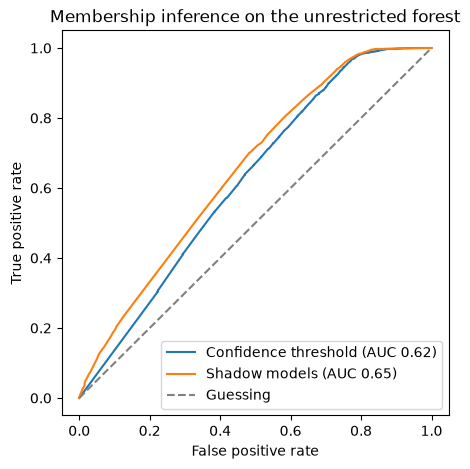

In [10]:
plt.figure(figsize=(5, 5))
for name, s in [('Confidence threshold', conf_scores), ('Shadow models', shadow_scores)]:
    fpr, tpr, _ = roc_curve(members, s)
    plt.plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(members, s):.2f})')
plt.plot([0, 1], [0, 1], '--', color='grey', label='Guessing')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Membership inference on the unrestricted forest')
plt.legend()
plt.savefig('figures/2_roc_attacks.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Defenses

| Defense | What changes |
|---|---|
| Round outputs | The model only reveals probabilities rounded to 1 decimal |
| Label only | The model only reveals its predicted label, no probabilities |
| Regularization | Train with `max_depth=10` so the model memorizes less |

In [11]:
def leak(scores):
    return round(roc_auc_score(members, scores), 3), round(tpr_at_fpr(members, scores), 3)

rounded_in = np.round(target.predict_proba(X_in), 1)[np.arange(len(y_in)), y_in]
rounded_out = np.round(target.predict_proba(X_out), 1)[np.arange(len(y_out)), y_out]
label_only = np.r_[target.predict(X_in) == y_in, target.predict(X_out) == y_out].astype(float)
regular = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=0, n_jobs=-1).fit(X_in, y_in)
regular_scores = np.r_[true_label_confidence(regular, X_in, y_in), true_label_confidence(regular, X_out, y_out)]

defenses = []
for name, model, scores in [('No defense', target, conf_scores),
                            ('Round outputs', target, np.r_[rounded_in, rounded_out]),
                            ('Label only', target, label_only),
                            ('Regularization (max_depth=10)', regular, regular_scores)]:
    auc, tpr = leak(scores)
    defenses.append({'defense': name, 'test_acc': round(accuracy_score(y_out, model.predict(X_out)), 3),
                     'attack_auc': auc, 'tpr_at_1pct_fpr': tpr})

defense_results = pd.DataFrame(defenses)
defense_results

,defense,test_acc,attack_auc,tpr_at_1pct_fpr
0,No defense,0.847,0.621,0.000
1,Round outputs,0.847,0.618,0.000
2,Label only,0.847,0.572,0.000
3,Regularization (max_depth=10),0.858,0.520,0.008


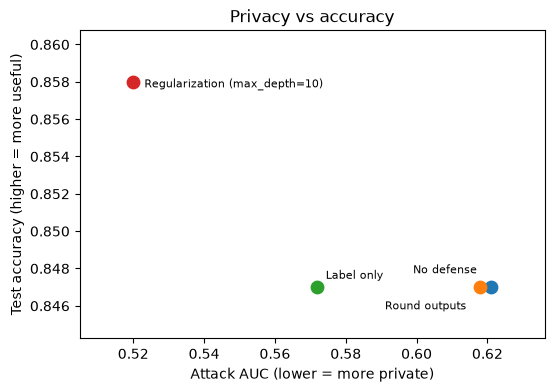

In [12]:
plt.figure(figsize=(6, 4))
offsets = {'No defense': (-10, 10), 'Round outputs': (-10, -16), 'Label only': (6, 6), 'Regularization (max_depth=10)': (8, -4)}
aligns = {'No defense': 'right', 'Round outputs': 'right', 'Label only': 'left', 'Regularization (max_depth=10)': 'left'}
for _, r in defense_results.iterrows():
    plt.scatter(r['attack_auc'], r['test_acc'], s=80)
    plt.annotate(r['defense'], (r['attack_auc'], r['test_acc']), textcoords='offset points',
                 xytext=offsets[r['defense']], ha=aligns[r['defense']], fontsize=8)
plt.margins(x=0.15, y=0.25)
plt.xlabel('Attack AUC (lower = more private)')
plt.ylabel('Test accuracy (higher = more useful)')
plt.title('Privacy vs accuracy')
plt.savefig('figures/3_privacy_vs_accuracy.png', dpi=200, bbox_inches='tight')
plt.show()

## 7. Who is most at risk?

Leakage is not equal for everyone. People whose records are unusual may be easier to identify. Here all 10,000 records (members and non-members) are split by how common their profile is: native country and occupation together.

In [13]:
adult_target, _ = train_test_split(adult, test_size=0.5, random_state=0)
adult_in, adult_out = train_test_split(adult_target, train_size=5000, test_size=5000, random_state=1)
both = pd.concat([adult_in, adult_out])
profile = both['native_country'] + ' / ' + both['occupation']
counts = profile.map(profile.value_counts())
group = np.where(counts.values < 20, 'Rare profile (<20 people)', 'Common profile')

risk = []
for g in ['Common profile', 'Rare profile (<20 people)']:
    mask = group == g
    risk.append({'group': g, 'people': int(mask.sum()),
                 'attack_auc': round(roc_auc_score(members[mask], conf_scores[mask]), 3)})
pd.DataFrame(risk)

,group,people,attack_auc
0,Common profile,9270,0.619
1,Rare profile (<20 people),730,0.640


## 8. Conclusions

**1. Overfitting drives privacy leakage.**
As `max_depth` increased from 2 to unlimited, attack AUC rose from 0.500 (random guessing) to 0.621. Leakage closely followed the gap between train and test accuracy, which grew from -0.002 to 0.145. The more a model memorizes its training data, the more it reveals who was in it.

**2. Shadow models give a stronger attack.**
The shadow model attack reached an AUC of 0.654, compared with 0.621 for the confidence threshold attack. At a strict 1% false positive rate, the shadow attack identified 2.5% of members, while the confidence attack identified none, because many members and non-members both received a confidence of exactly 1.0.

**3. Regularization was the best defense, at no cost.**
| Defense | Test accuracy | Attack AUC |
|---|---|---|
| No defense | 0.847 | 0.621 |
| Round outputs | 0.847 | 0.618 |
| Label only | 0.847 | 0.572 |
| Regularization (max_depth=10) | 0.858 | 0.520 |

Rounding outputs had almost no effect. Returning only labels reduced leakage but did not remove it. Limiting tree depth brought the attack close to random guessing and also improved test accuracy, since the unrestricted model was overfitting. In this setting, privacy and accuracy were not in conflict.

**4. People with rare profiles appear more exposed.**
Records whose native country and occupation combination was shared by fewer than 20 people had a slightly higher attack AUC (0.640) than common profiles (0.619). The gap is small and comes from a single split, so it should be confirmed with repeated runs, but it is consistent with the idea that unusual individuals are easier to identify.

## Limitations
- All results come from a single random split. Repeating with several seeds would give error bars.
- Only random forests on one tabular dataset were tested.
- The attacker is assumed to know the target model type.

## Future work
- Add a differential privacy defense (DP-SGD with a neural network using Opacus) and compare its privacy–accuracy trade-off with regularization
- Implement a stronger attack such as LiRA (Carlini et al., 2022), which uses many shadow models per record
- Repeat the experiments with neural networks and image data